# Baseline de clasificación de letalidad

Este notebook establece una línea base supervisada para clasificar el desenlace de los eventos. La variable objetivo es `lethal` (1 = letal, 0 = positivo no letal); los registros sin desenlace clasificado se excluyen antes de la partición. La evaluación se enfoca en la clase minoritaria no letal, además de reportar métricas macro y matrices de confusión.

**Prevención estricta de data leakage:** se excluyen `total_deaths`, `total_deaths_missing`, `total_killed_and_disposed_of`, `outcome`, `lethal` y `certified` de los predictores. También se excluyen identificadores, fechas originales y variables fuera del conjunto de características definido. El preprocesamiento se ajusta dentro de pipelines usando exclusivamente el conjunto de entrenamiento.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

In [2]:
dataset_candidates = [
    Path("datos/avian_clean.csv"),
    Path("../datos/avian_clean.csv"),
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f"No se encontró datos/avian_clean.csv desde {Path.cwd()}. "
        "Ejecuta primero codigo/01_limpieza.ipynb."
    )

source_df = pd.read_csv(dataset_path)
if "lethal" in source_df.columns:
    target_raw = pd.to_numeric(source_df["lethal"], errors="coerce")
elif "outcome" in source_df.columns:
    target_raw = source_df["outcome"].map({"death": 1, "positive": 0})
else:
    raise ValueError("El dataset debe incluir 'lethal' o 'outcome' para definir el objetivo.")

if "outcome" in source_df.columns:
    mapped_outcome = source_df["outcome"].map({"death": 1, "positive": 0})
    comparable = target_raw.notna() & mapped_outcome.notna()
    if not target_raw.loc[comparable].astype(int).equals(
        mapped_outcome.loc[comparable].astype(int)
    ):
        raise ValueError("'lethal' y 'outcome' contienen etiquetas clasificadas inconsistentes.")

classified_mask = target_raw.notna()
df = source_df.loc[classified_mask].copy()
df["target_lethal"] = target_raw.loc[classified_mask].astype(int)
if not set(df["target_lethal"].unique()).issubset({0, 1}):
    raise ValueError("La variable objetivo debe contener únicamente las clases 0 y 1.")

if "start_date_outbreak" not in df.columns:
    raise ValueError("Falta la columna requerida 'start_date_outbreak'.")
df["start_date_outbreak"] = pd.to_datetime(
    df["start_date_outbreak"], errors="coerce"
)

print(f"Archivo: {dataset_path.resolve()}")
print(f"Registros originales: {len(source_df):,}")
print(f"Registros sin desenlace clasificado excluidos: {(~classified_mask).sum():,}")
print(f"Registros para modelar: {len(df):,}")
display(
    df["target_lethal"]
    .value_counts()
    .sort_index()
    .rename(index={0: "No letal (0)", 1: "Letal (1)"})
    .rename("eventos")
    .to_frame()
    .assign(porcentaje=lambda table: table["eventos"] / len(df) * 100)
    .style.format({"porcentaje": "{:.1f}%"})
)

Archivo: C:\Users\matta\Desktop\UNIVERSIDAD\2026-2\MDD\mdd-proyecto\datos\avian_clean.csv
Registros originales: 379
Registros sin desenlace clasificado excluidos: 16
Registros para modelar: 363


,eventos,porcentaje
target_lethal,,
No letal (0),34,9.4%
Letal (1),329,90.6%


In [3]:
required_features = {
    "species_group",
    "country_name",
    "log_cases",
    "total_cases_missing",
    "start_date_outbreak",
}
missing_features = required_features.difference(df.columns)
if missing_features:
    raise ValueError("Faltan predictores requeridos: " + ", ".join(sorted(missing_features)))

df["start_year"] = df["start_date_outbreak"].dt.year
df["start_month"] = df["start_date_outbreak"].dt.month
control_features = sorted(
    column
    for column in df.columns
    if column.startswith("ctl_") and column != "ctl_count"
)
feature_columns = [
    "species_group",
    "country_name",
    "start_year",
    "start_month",
    "log_cases",
    "total_cases_missing",
    *control_features,
]
X = df[feature_columns].copy()
y = df["target_lethal"].copy()

forbidden_predictors = {
    "total_deaths",
    "total_deaths_missing",
    "total_killed_and_disposed_of",
    "outcome",
    "lethal",
    "certified",
}
identifier_columns = {
    "report_id",
    "event_id",
    "outbreak_reference",
    "label_id",
}
leakage_in_X = forbidden_predictors.intersection(X.columns)
identifiers_in_X = identifier_columns.intersection(X.columns)
if leakage_in_X:
    raise ValueError(f"Se detectaron predictores con fuga de información: {sorted(leakage_in_X)}")
if identifiers_in_X:
    raise ValueError(f"Se detectaron identificadores como predictores: {sorted(identifiers_in_X)}")
if not X.columns.is_unique or y.nunique() != 2:
    raise ValueError("Verifica que los predictores sean únicos y existan ambas clases objetivo.")

excluded_columns = sorted(set(df.columns).difference(X.columns))
print("Predictores incluidos:", X.columns.tolist())
print("Columnas descartadas (incluye objetivo, variables prohibidas, IDs y otras fuera del alcance):")
print(excluded_columns)
print("Columnas prohibidas presentes en X:", sorted(leakage_in_X))
print("Identificadores presentes en X:", sorted(identifiers_in_X))

Predictores incluidos: ['species_group', 'country_name', 'start_year', 'start_month', 'log_cases', 'total_cases_missing', 'ctl_disinfection', 'ctl_disposal', 'ctl_none', 'ctl_quarantine', 'ctl_screening', 'ctl_selective_kill', 'ctl_stamping_out', 'ctl_surv_outside', 'ctl_surv_within', 'ctl_unknown', 'ctl_wildlife_ctrl', 'ctl_zoning']
Columnas descartadas (incluye objetivo, variables prohibidas, IDs y otras fuera del alcance):
['certified', 'control_measures', 'country_iso3_letter', 'ctl_count', 'duration_days', 'end_date_outbreak', 'epidemiological_unit', 'event_id', 'first_administrative_division', 'first_result_date_1', 'first_result_date_2', 'genotype_serotype_subtype', 'is_bird', 'is_farmed_wild_species', 'label_id', 'laboratory_name_1', 'laboratory_name_2', 'latest_result_date_1', 'latest_result_date_2', 'latitude', 'lethal', 'location', 'longitude', 'outbreak_reference', 'outcome', 'report_date', 'report_id', 'result_1', 'result_2', 'second_administrative_division', 'species', 's

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train: {len(X_train):,} registros | Test: {len(X_test):,} registros")
print("Proporción de clases en train:")
display(y_train.value_counts(normalize=True).sort_index().rename("proporción").to_frame())
print("Proporción de clases en test:")
display(y_test.value_counts(normalize=True).sort_index().rename("proporción").to_frame())

Train: 272 registros | Test: 91 registros
Proporción de clases en train:


,proporción
target_lethal,
0,0.091912
1,0.908088


Proporción de clases en test:


,proporción
target_lethal,
0,0.098901
1,0.901099


In [5]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
unassigned_features = set(X.columns).difference(numeric_features, categorical_features)
if unassigned_features:
    raise TypeError(f"Hay predictores sin estrategia de preprocesamiento: {sorted(unassigned_features)}")

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

print("Predictores numéricos:", numeric_features)
print("Predictores categóricos:", categorical_features)

Predictores numéricos: ['start_year', 'start_month', 'log_cases', 'total_cases_missing', 'ctl_disinfection', 'ctl_disposal', 'ctl_none', 'ctl_quarantine', 'ctl_screening', 'ctl_selective_kill', 'ctl_stamping_out', 'ctl_surv_outside', 'ctl_surv_within', 'ctl_unknown', 'ctl_wildlife_ctrl', 'ctl_zoning']
Predictores categóricos: ['species_group', 'country_name']


In [6]:
metric_rows = []
fitted_models = {}
confusion_matrices = {}
minority_scores = {}


def fit_and_evaluate(name, estimator):
    fitted_model = estimator.fit(X_train, y_train)
    predictions = fitted_model.predict(X_test)
    if not hasattr(fitted_model, "predict_proba"):
        raise TypeError(f"El modelo {name} no proporciona probabilidades para la curva Precision-Recall.")

    classes = list(fitted_model.classes_)
    if 0 not in classes:
        raise ValueError(f"El modelo {name} no incluye la clase minoritaria 0 en entrenamiento.")
    scores_for_class_zero = fitted_model.predict_proba(X_test)[:, classes.index(0)]
    minority_truth = (y_test == 0).astype(int)
    metrics = {
        "modelo": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision_macro": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(y_test, predictions, average="macro", zero_division=0),
        "Precision_clase_0": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Recall_clase_0": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "F1_clase_0": f1_score(y_test, predictions, pos_label=0, zero_division=0),
        "Precision_clase_1": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Recall_clase_1": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1_clase_1": f1_score(y_test, predictions, pos_label=1, zero_division=0),
        "AP_clase_0": average_precision_score(minority_truth, scores_for_class_zero),
    }

    metric_rows.append(metrics)
    fitted_models[name] = fitted_model
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])
    minority_scores[name] = scores_for_class_zero
    return metrics


dummy_metrics = fit_and_evaluate(
    "Dummy (most_frequent)",
    DummyClassifier(strategy="most_frequent"),
)
display(pd.DataFrame([dummy_metrics]).set_index("modelo").round(3))
print("Clase predicha por Dummy:", fitted_models["Dummy (most_frequent)"].classes_[
    np.argmax(fitted_models["Dummy (most_frequent)"].class_prior_)
])
assert dummy_metrics["F1_clase_0"] == 0.0

,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_clase_0,Recall_clase_0,F1_clase_0,Precision_clase_1,Recall_clase_1,F1_clase_1,AP_clase_0
modelo,,,,,,,,,,,
Dummy (most_frequent),0.901,0.451,0.5,0.474,0.0,0.0,0.0,0.901,1.0,0.948,0.099


Clase predicha por Dummy: 1


In [7]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
logistic_metrics = fit_and_evaluate("Regresión logística", logistic_pipeline)
display(pd.DataFrame([logistic_metrics]).set_index("modelo").round(3))

,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_clase_0,Recall_clase_0,F1_clase_0,Precision_clase_1,Recall_clase_1,F1_clase_1,AP_clase_0
modelo,,,,,,,,,,,
Regresión logística,0.868,0.704,0.877,0.747,0.421,0.889,0.571,0.986,0.866,0.922,0.581


In [8]:
knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]
)

knn_metrics = fit_and_evaluate("K-NN (k=5)", knn_pipeline)
display(pd.DataFrame([knn_metrics]).set_index("modelo").round(3))

,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_clase_0,Recall_clase_0,F1_clase_0,Precision_clase_1,Recall_clase_1,F1_clase_1,AP_clase_0
modelo,,,,,,,,,,,
K-NN (k=5),0.912,0.765,0.654,0.69,0.6,0.333,0.429,0.93,0.976,0.952,0.292


In [9]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
                class_weight="balanced",
            ),
        ),
    ]
)

random_forest_metrics = fit_and_evaluate("Random Forest", random_forest_pipeline)
display(pd.DataFrame([random_forest_metrics]).set_index("modelo").round(3))

,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_clase_0,Recall_clase_0,F1_clase_0,Precision_clase_1,Recall_clase_1,F1_clase_1,AP_clase_0
modelo,,,,,,,,,,,
Random Forest,0.89,0.712,0.791,0.741,0.462,0.667,0.545,0.962,0.915,0.938,0.512


Comparación de métricas en test (clase 0 = no letal):


,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_clase_0,Recall_clase_0,F1_clase_0,Precision_clase_1,Recall_clase_1,F1_clase_1,AP_clase_0
modelo,,,,,,,,,,,
Regresión logística,0.868,0.704,0.877,0.747,0.421,0.889,0.571,0.986,0.866,0.922,0.581
Random Forest,0.890,0.712,0.791,0.741,0.462,0.667,0.545,0.962,0.915,0.938,0.512
K-NN (k=5),0.912,0.765,0.654,0.690,0.600,0.333,0.429,0.930,0.976,0.952,0.292
Dummy (most_frequent),0.901,0.451,0.500,0.474,0.000,0.000,0.000,0.901,1.000,0.948,0.099


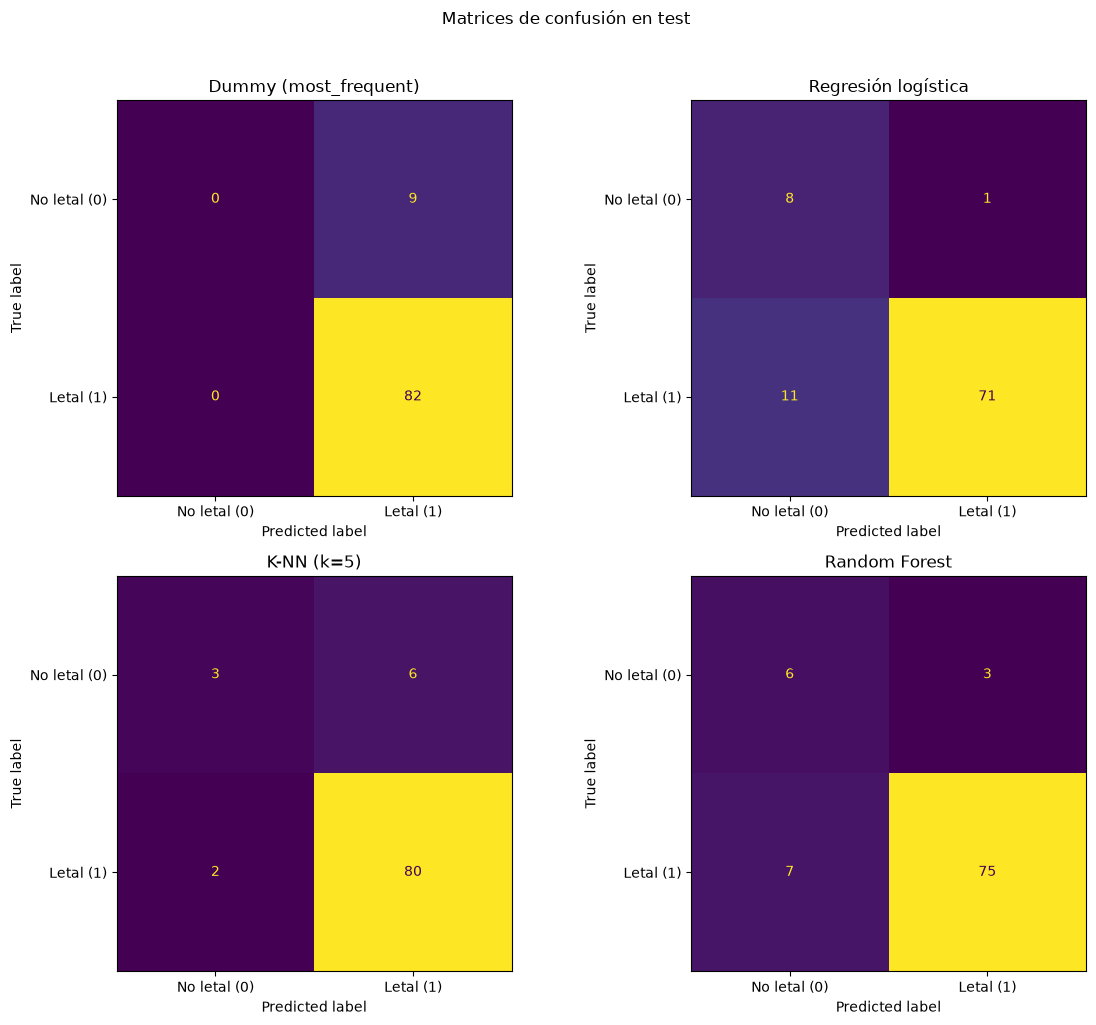

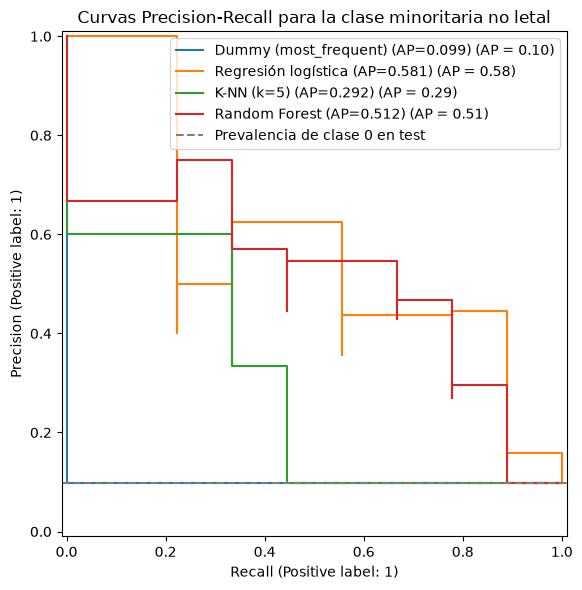

Mejor balance según F1 macro (desempate por F1 y AP de clase 0): Regresión logística. F1_macro=0.747, F1_clase_0=0.571, Recall_clase_0=0.889, AP_clase_0=0.581.


In [10]:
summary = pd.DataFrame(metric_rows).set_index("modelo")
metric_columns = [
    "Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "Precision_clase_0",
    "Recall_clase_0",
    "F1_clase_0",
    "Precision_clase_1",
    "Recall_clase_1",
    "F1_clase_1",
    "AP_clase_0",
]
print("Comparación de métricas en test (clase 0 = no letal):")
display(summary[metric_columns].sort_values("F1_macro", ascending=False).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, matrix) in zip(axes.ravel(), confusion_matrices.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["No letal (0)", "Letal (1)"],
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)
for ax in axes.ravel()[len(confusion_matrices):]:
    ax.set_visible(False)
fig.suptitle("Matrices de confusión en test", y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, scores in minority_scores.items():
    PrecisionRecallDisplay.from_predictions(
        (y_test == 0).astype(int),
        scores,
        name=f"{name} (AP={summary.loc[name, 'AP_clase_0']:.3f})",
        ax=ax,
    )
ax.axhline(
    (y_test == 0).mean(),
    color="gray",
    linestyle="--",
    label="Prevalencia de clase 0 en test",
)
ax.set_title("Curvas Precision-Recall para la clase minoritaria no letal")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

best_model_name = summary.sort_values(
    ["F1_macro", "F1_clase_0", "AP_clase_0"],
    ascending=False,
).index[0]
best_metrics = summary.loc[best_model_name]
print(
    f"Mejor balance según F1 macro (desempate por F1 y AP de clase 0): {best_model_name}. "
    f"F1_macro={best_metrics['F1_macro']:.3f}, "
    f"F1_clase_0={best_metrics['F1_clase_0']:.3f}, "
    f"Recall_clase_0={best_metrics['Recall_clase_0']:.3f}, "
    f"AP_clase_0={best_metrics['AP_clase_0']:.3f}."
)

## Análisis y conclusiones

- **Accuracy no basta:** con cerca de 90,6% de eventos letales, predecir siempre la clase mayoritaria ya produce un accuracy alto, aunque no identifique ningún evento no letal. Por eso se comparan F1 macro, precisión/recall por clase, F1 de la clase 0 y Average Precision para la clase minoritaria. En el Dummy, las probabilidades de la clase 0 son constantes en cero: su Average Precision coincide con la prevalencia de esa clase en test y no representa capacidad de ranking. La curva Precision-Recall resultante es degenerada; no debe interpretarse como evidencia predictiva.
- **Balance entre clases:** usa la tabla y la salida de la última celda para identificar el modelo con mayor F1 macro; el desempate se resuelve por F1 y Average Precision de la clase 0. Revisa junto a ese ranking la matriz de confusión y el recall de no letales, pues cada error puede tener implicaciones distintas. El test contiene pocos ejemplos no letales, por lo que las métricas pueden variar considerablemente con otra partición.
- **Alcance del baseline:** esta partición estratificada entrega una primera referencia comparativa, no una estimación definitiva de generalización ni evidencia causal. En etapas siguientes conviene complementar con validación cruzada estratificada y análisis de incertidumbre, manteniendo la separación entre entrenamiento y evaluación. `country_name` se codifica con una columna por categoría; países con pocos eventos pueden producir indicadores escasos y alta dimensionalidad. `handle_unknown="ignore"` permite categorías nuevas en test. Si los modelos avanzados muestran sobreajuste, se puede evaluar agrupar países poco frecuentes en `Other`, definiendo esa agrupación dentro del entrenamiento de cada partición.
- **Modelos avanzados:** la Red Bayesiana puede explorar dependencias condicionales entre características y desenlace, respetando la exclusión de variables que revelen directamente el resultado. El clustering es no supervisado: puede ayudar a descubrir perfiles de eventos y luego describir su composición, pero no se compara directamente con estas métricas de clasificación.

**Nota:** los resultados describen asociaciones en los reportes disponibles. No deben interpretarse como causalidad ni como tasas poblacionales de letalidad.